<a href="https://colab.research.google.com/github/AnanyaAsthana/Data-Mining-Warehousing-Lab/blob/main/lab_7_dwm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving 04_olap_sales_dataset.csv to 04_olap_sales_dataset.csv
First 5 rows:
  Order_ID        Date  Year  Quarter  Month Region      City   Product  \
0    O0001  2025-07-25  2025        3      7   East     Delhi  Keyboard   
1    O0002  2025-01-24  2025        1      1   West    Ujjain     Phone   
2    O0003  2025-10-17  2025        4     10  North  Jabalpur  Keyboard   
3    O0004  2025-11-13  2025        4     11  South  Jabalpur  Keyboard   
4    O0005  2025-05-11  2025        2      5  North    Ujjain  Keyboard   

    Category  Quantity  Unit_Price  Revenue  
0  Accessory         3        1800     5400  
1     Mobile         7       22000   154000  
2  Accessory         4        1800     7200  
3  Accessory         1        1800     1800  
4  Accessory         7        1800    12600  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      -------------

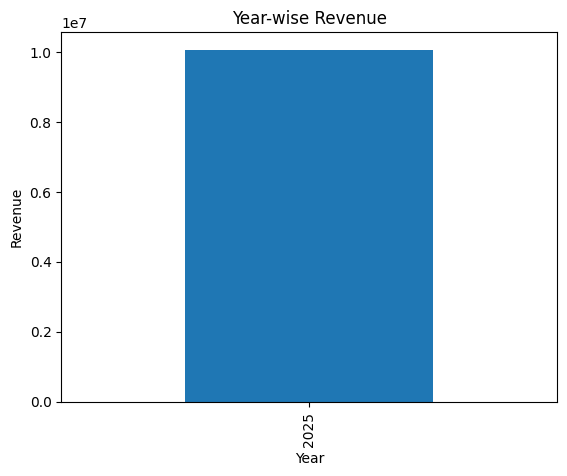


CONCLUSION:
OLAP operations help analyze multidimensional data.
Roll-up summarizes data, drill-down provides details,
slice selects one dimension value, and dice selects
multiple dimension values.


In [2]:

# EXPERIMENT 4: OLAP OPERATIONS

import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('04_olap_sales_dataset.csv')

# Display dataset
print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

# 1. Total Revenue and Quantity
print("\nTOTAL REVENUE:", df['Revenue'].sum())
print("TOTAL QUANTITY:", df['Quantity'].sum())


# 2. ROLL-UP: Revenue by Year
print("\nROLL-UP: Revenue by Year")
rollup_year = df.groupby('Year')['Revenue'].sum()
print(rollup_year)

# Roll-up: Revenue by Region
print("\nROLL-UP: Revenue by Region")
rollup_region = df.groupby('Region')['Revenue'].sum()
print(rollup_region)


# 3. DRILL-DOWN: Year -> Quarter -> Month
print("\nDRILL-DOWN: Revenue by Year, Quarter and Month")

drilldown = df.groupby(
    ['Year', 'Quarter', 'Month']
)['Revenue'].sum().reset_index()

print(drilldown)


# 4. SLICE: Select one Year
print("\nSLICE: Sales for Year 2025")

slice_data = df[df['Year'] == 2025]
print(slice_data)

print("\nRevenue for 2025:", slice_data['Revenue'].sum())


# 5. DICE: Select multiple Regions and Products
print("\nDICE: Selected Regions and Products")

dice_data = df[
    (df['Region'].isin(['East', 'West'])) &
    (df['Product'].isin(['Phone', 'Laptop']))
]

print(dice_data)

print("\nDice Revenue:", dice_data['Revenue'].sum())


# 6. PIVOT TABLE
print("\nPIVOT TABLE: Revenue by Region and Product")

pivot = pd.pivot_table(
    df,
    values='Revenue',
    index='Region',
    columns='Product',
    aggfunc='sum',
    fill_value=0
)

print(pivot)


# 7. VISUALIZATION
rollup_year.plot(kind='bar', title='Year-wise Revenue')

plt.xlabel('Year')
plt.ylabel('Revenue')
plt.show()

print("\nCONCLUSION:")
print("OLAP operations help analyze multidimensional data.")
print("Roll-up summarizes data, drill-down provides details,")
print("slice selects one dimension value, and dice selects")
print("multiple dimension values.")
